# The Hedge That Leaked: notebook

Companion to the article on [mathforfinance.com](https://mathforfinance.com). Every number and chart in the article is produced here from the raw files in `data/raw/` (repo root).

**Question:** a trader is long \$100mm of the on-the-run 10-year Treasury note and hedges by selling Treasury futures. How well does each hedge hold up when the curve twists, as it did around the failure of Silicon Valley Bank (10–13 March 2023)?

Hedges compared (rebalanced daily, using only information available that day):
1. DV01 match with TY, CME's "10-Year" contract, whose cheapest-to-deliver is a ~7-year note
2. DV01 match with UXY, the Ultra 10-Year (CME code TN), whose cheapest-to-deliver is a ~10-year note
3. Key-rate hedge with FV, TY and UXY, matching risk in 1-5y, 7y and 10-30y buckets (Ho, 1992)
4. PCA hedge neutralising level and slope with FV and UXY (Litterman and Scheinkman, 1991)

Run order: `src/validate_cf.py` → `src/experiment.py` → `src/figures.py` → `src/validation.py`. The cells below do exactly that.

In [1]:
import sys, json, pathlib
sys.path.insert(0, str(pathlib.Path('src').resolve()))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
ART = pathlib.Path("src").resolve().parent; SRC = str(ART/"src")
import mff_rates   # moves the working directory to the repo root
print('working dir:', pathlib.Path.cwd())

working dir: /home/claude/repo


## 1. Raw data snapshot
What each file is and where it came from is listed in `data/README.md`.

In [2]:
for f in sorted(pathlib.Path('data/raw').iterdir()):
    print(f'{f.name:70s} {f.stat().st_size/1e3:8.1f} kB')

cme_treasury_conversion_factors_TCF_2026-10-21.xlsx                       785.6 kB
fed_gsw_nominal_curve_2021_2023H1.csv                                     116.9 kB
fedinvest_prices_2023-01.csv                                              484.2 kB
fedinvest_prices_2023-02.csv                                              459.5 kB
fedinvest_prices_2023-03.csv                                              558.4 kB
nyfed_sofr_2023.csv                                                         3.0 kB
nyfed_tgcr_2023.csv                                                         2.9 kB
treasury_par_yield_curve_2021.csv                                          17.9 kB
treasury_par_yield_curve_2022.csv                                          18.2 kB
treasury_par_yield_curve_2023.csv                                          19.1 kB
treasurydirect_auctions_notes_bonds_2010_2023Q1.csv                        78.0 kB
yahoo_TN_front_continuous_2023Q1.csv                                        3.8 kB
yaho

## 2. Check the conversion-factor formula against CME's published table
CME publishes conversion factors for every deliverable note and bond for currently listed contracts. If our formula is right, every one should match to 4 decimals.

In [3]:
%run {SRC}/validate_cf.py

contracts: {'3YR': 65, 'FV': 15, 'TN': 3, 'TU': 50, 'TWE': 33, 'TY': 68, 'UB': 190, 'US': 1770}
rows: 2194  exact matches: 2194  max |diff|: 0.0
Empty DataFrame
Columns: [contract, coupon, issue, maturity, cusip, delivery, cme_cf, our_cf, diff]
Index: []


## 3. Run the hedge experiment (Q1 2023, daily)
Fits a Svensson curve to FedInvest prices each day, values FV/TY/UXY futures from the cheapest-to-deliver forward price, computes key-rate risk, PCA loadings (250 days of par-yield changes up to that day), hedge ratios, next-day P&L and its decomposition. Takes a few minutes.

In [4]:
%run {SRC}/experiment.py

2023-01-03 91282CFV8 Mar23 done


2023-01-04

 91282CFV8 Mar23 done


2023-01-05 91282CFV8 Mar23 done


2023-01-06 91282CFV8 Mar23 done


...

2023-03-24 91282CGM7 Jun23 done


2023-03-27 91282CGM7 Jun23 done


2023-03-28 91282CGM7 Jun23 done


2023-03-29 91282CGM7 Jun23 done


2023-03-30 91282CGM7 Jun23 done


In [5]:
h = pd.read_csv('data/derived/daily_hedge_pnl.csv', parse_dates=['date','start'])
event = h[(h.start >= '2023-03-08') & (h.date <= '2023-03-13')]
cols = ['pnl','pc1','pc2','pc3','curve_resid','other_pnl']
(event.groupby('hedge')[cols].sum()/1e3).round(0).rename(columns={'pnl':'total $k','pc1':'level','pc2':'slope','pc3':'curvature','curve_resid':'other curve','other_pnl':'carry/financing/basis'})

,total $k,level,slope,curvature,other curve,carry/financing/basis
hedge,,,,,,
"DV01 hedge, TY",-906.0,-442.0,-1009.0,263.0,369.0,-87.0
"DV01 hedge, UXY",-74.0,-43.0,-110.0,25.0,119.0,-65.0
Key-rate hedge (FV+TY+UXY),21.0,3.0,-8.0,-2.0,90.0,-63.0
"PCA hedge, level+slope (FV+UXY)",51.0,0.0,-0.0,4.0,124.0,-77.0
Unhedged,3456.0,5333.0,-1360.0,-105.0,-586.0,175.0


### Out-of-sample hedge error
Each day's hedge uses only that day's prices and the trailing 250-day PCA. Below: standard deviation of daily hedged P&L, whole of Q1 2023 and March only.

In [6]:
stats = pd.DataFrame({
  'Q1 daily std $k': h.groupby('hedge').pnl.std()/1e3,
  'March daily std $k': h[h.date >= '2023-03-01'].groupby('hedge').pnl.std()/1e3,
  'worst day $k': h.groupby('hedge').pnl.min()/1e3,
  '8-13 Mar total $k': event.groupby('hedge').pnl.sum()/1e3}).round(0)
stats

,Q1 daily std $k,March daily std $k,worst day $k,8-13 Mar total $k
hedge,,,,
"DV01 hedge, TY",166.0,232.0,-547.0,-906.0
"DV01 hedge, UXY",24.0,33.0,-60.0,-74.0
Key-rate hedge (FV+TY+UXY),26.0,37.0,-52.0,21.0
"PCA hedge, level+slope (FV+UXY)",25.0,36.0,-57.0,51.0
Unhedged,695.0,830.0,-1285.0,3456.0


In [7]:
r = pd.read_csv('data/derived/daily_risk_snapshot.csv', parse_dates=['date']).set_index('date')
r.loc['2023-03-08'].to_frame('8 Mar 2023')

,8 Mar 2023
cusip,91282CGM7
contract,Jun23
bond_krd_1y,377.608552
bond_krd_2y,634.06155
bond_krd_3y,1500.933486
bond_krd_5y,2825.517073
bond_krd_7y,6090.684497
bond_krd_10y,69902.077496
bond_krd_20y,-0.000165
bond_krd_30y,-0.000165


## 4. Charts

ok


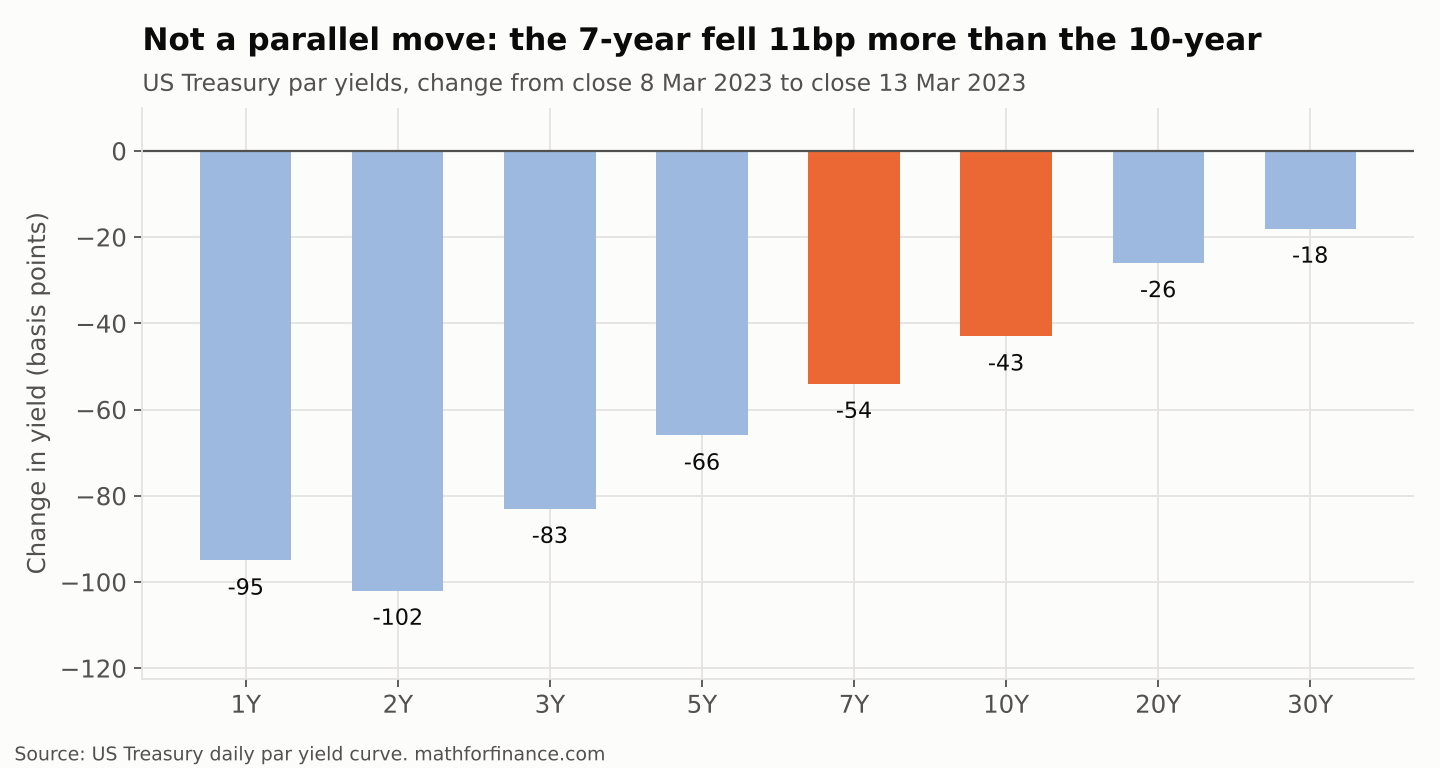

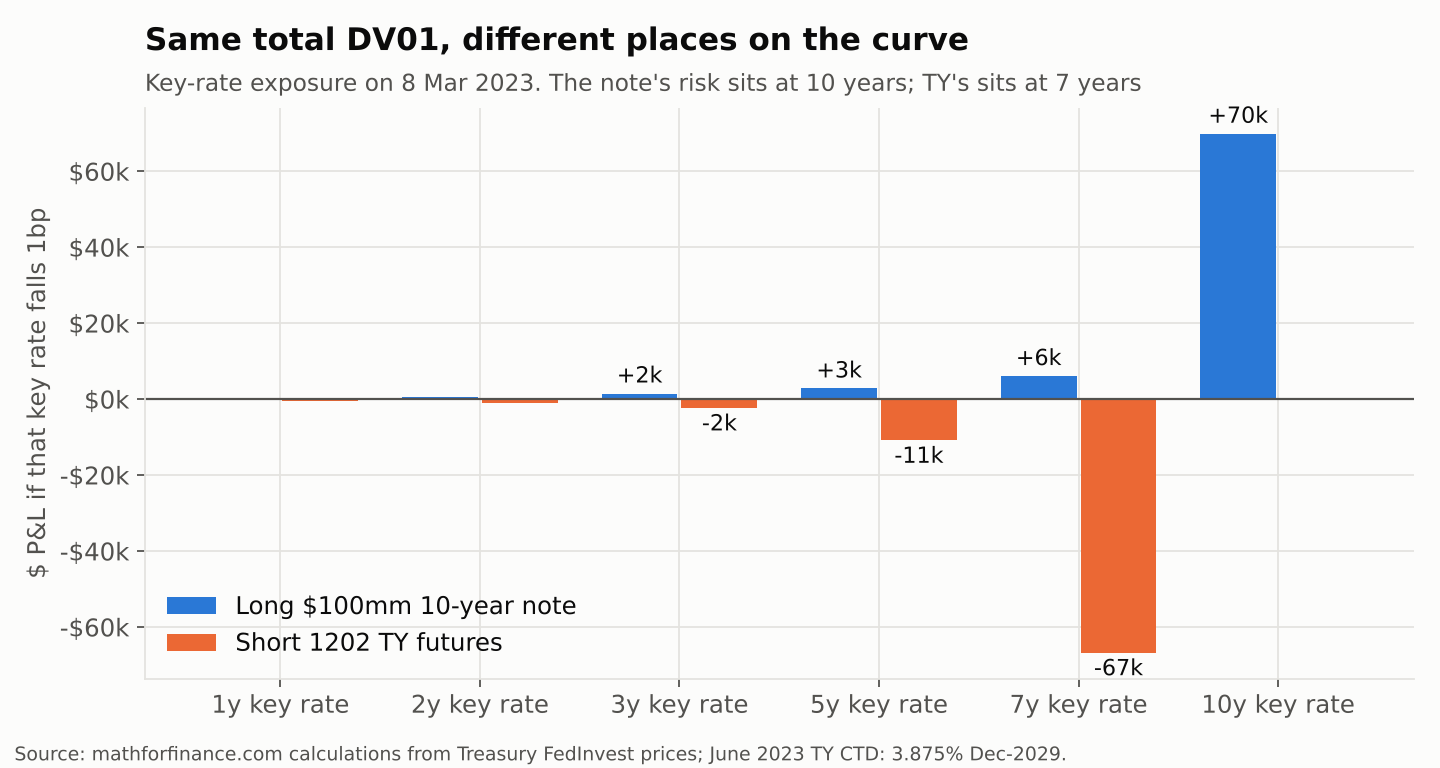

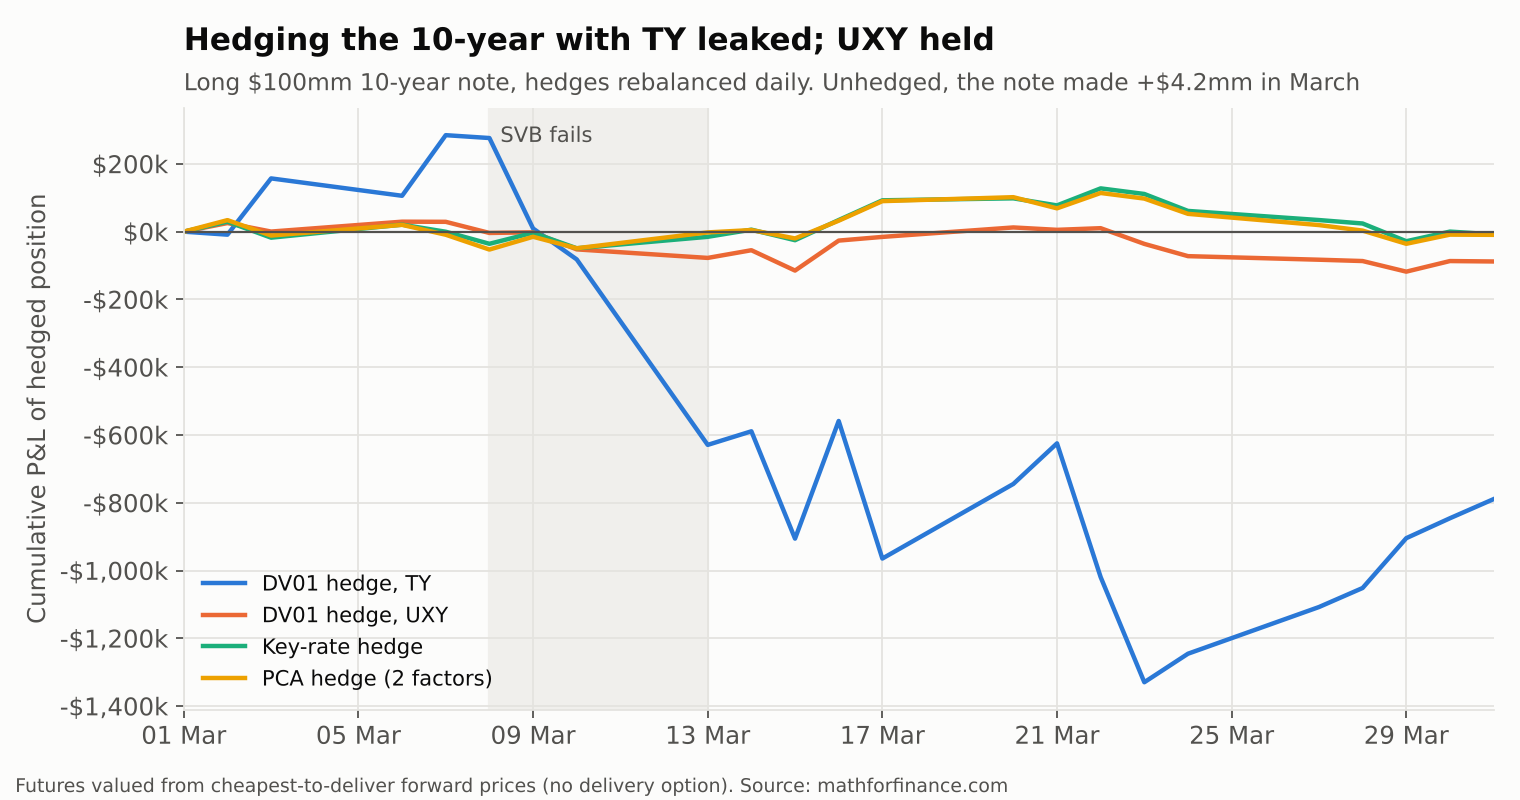

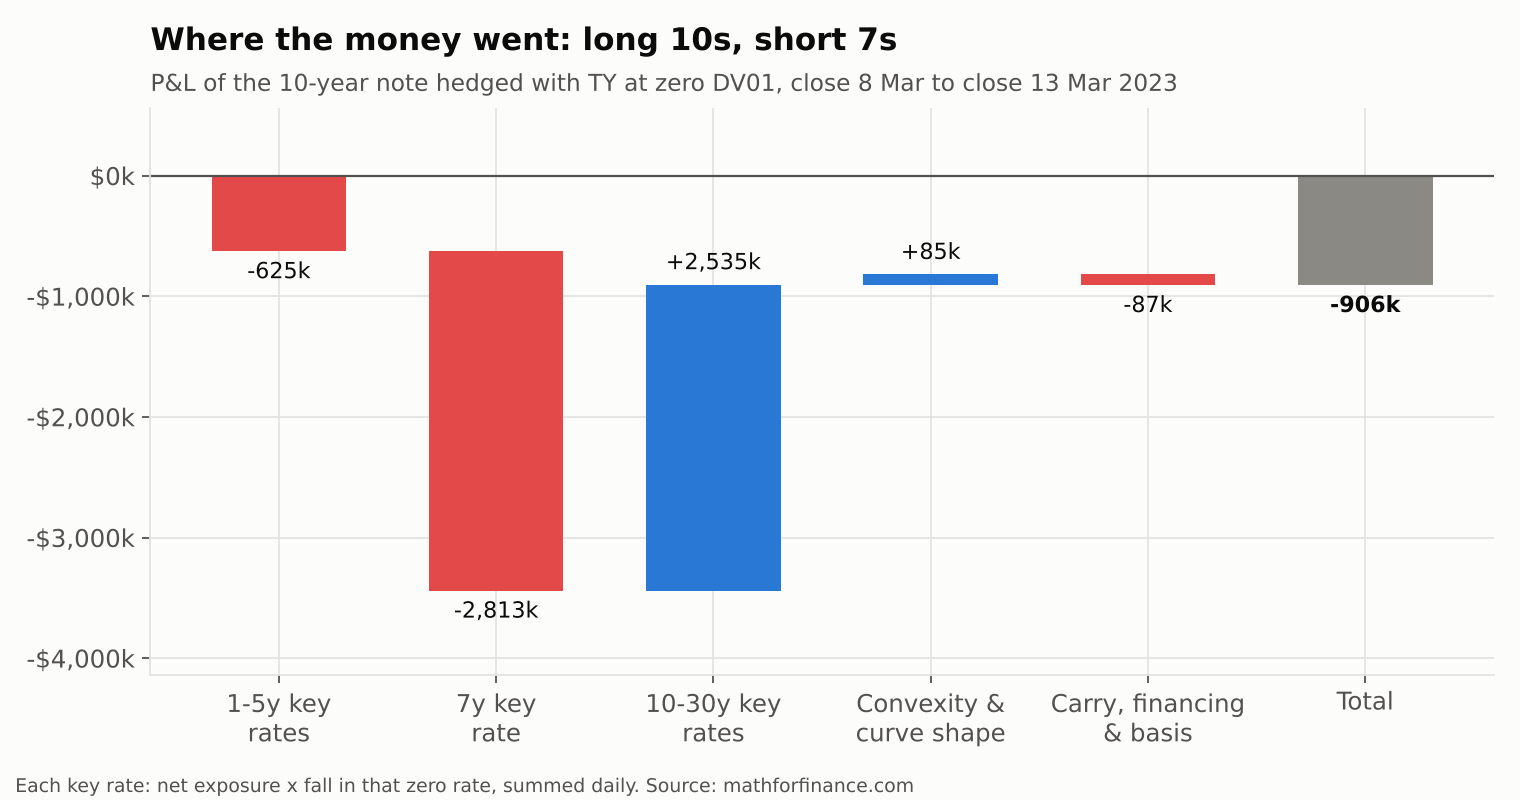

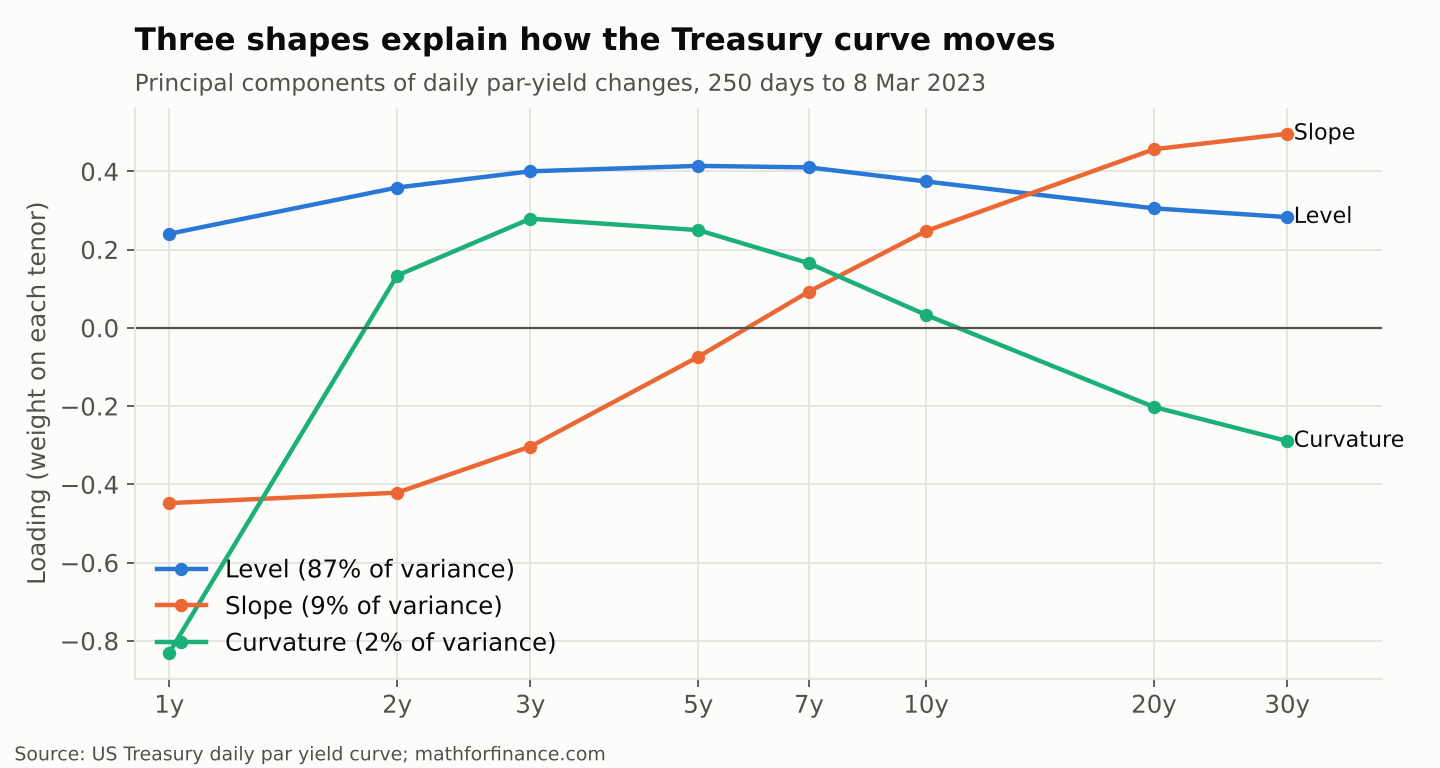

In [8]:
%run {SRC}/figures.py
for f in sorted((ART/'figures').glob('*.png')):
    display(Image(filename=str(f), width=820))

## 5. Independent checks
- Conversion factors and baskets vs CME's table
- Theoretical futures vs Yahoo Finance daily closes (front contract; third-party data, used only as a check)
- Our fitted curve vs the Federal Reserve's Gürkaynak–Sack–Wright curve
- The P&L decomposition adds back to the total

In [9]:
%run {SRC}/validation.py

{
 "cf_rows": 2194,
 "cf_exact": 2194,
 "baskets": {
  "TU": {
   "cme": 50,
   "ours": 50,
   "only_cme": 0,
   "only_ours": 0
  },
  "FV": {
   "cme": 15,
   "ours": 15,
   "only_cme": 0,
   "only_ours": 0
  },
  "TY": {
   "cme": 68,
   "ours": 68,
   "only_cme": 0,
   "only_ours": 0
  },
  "TN": {
   "cme": 3,
   "ours": 3,
   "only_cme": 0,
   "only_ours": 0
  }
 },
 "futures_vs_yahoo": {
  "FV 2023-03": {
   "n": 37,
   "mean": -0.61,
   "mean_abs": 0.99,
   "max_abs": 3.42
  },
  "FV 2023-06": {
   "n": 7,
   "mean": 0.97,
   "mean_abs": 3.83,
   "max_abs": 13.93
  },
  "TN 2023-03": {
   "n": 37,
   "mean": 0.76,
   "mean_abs": 1.66,
   "max_abs": 5.14
  },
  "TN 2023-06": {
   "n": 7,
   "mean": 1.05,
   "mean_abs": 2.66,
   "max_abs": 6.84
  },
  "TU 2023-03": {
   "n": 37,
   "mean": -1.49,
   "mean_abs": 1.49,
   "max_abs": 3.06
  },
  "TU 2023-06": {
   "n": 7,
   "mean": 5.31,
   "mean_abs": 5.31,
   "max_abs": 7.68
  },
  "TY 2023-03": {
   "n": 37,
   "mean": -0.52,
   

## Limitations (read before using this for anything real)
- Futures are valued at the cheapest-to-deliver forward price with an overnight repo rate (TGCR) held flat to delivery. This ignores the futures seller's delivery options and term-repo, so it overstates the futures price slightly; the check against Yahoo closes shows the size of the gap.
- FedInvest end-of-day prices and futures closes are not taken at the same moment.
- PCA factors are estimated on **par** yields and applied to **zero-rate** key shocks; this is a standard practical shortcut, not an exact mapping.
- Transaction costs and bid/offer are ignored. The note is financed in repo at TGCR.